In [1]:
!pip install torch_geometric
!pip install rdkit

import torch
import torch.nn.functional as F
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch_geometric.data import Data, DataLoader as GeoLoader
from torch_geometric.nn import GINConv, global_mean_pool
from rdkit import Chem
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import random, pickle, warnings
warnings.filterwarnings('ignore')

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 27.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 23.6 MB/s eta 0:00:00
device: cuda


In [2]:
# ============================================================
# Cell 1: 公共组件（Dataset / 模型 / 训练函数 / baseline 诊断）
# ============================================================

class DrugResponseDataset(Dataset):
    def __init__(self, df, y_mean=None, y_std=None):
        self.cell_cols = [c for c in df.columns if c.startswith(('PCA_', 'MUT_', 'MGMT_'))]
        self.fingerprints = torch.tensor(np.stack(df['Morgan_FP'].values), dtype=torch.float32)
        self.cell_features = torch.tensor(
            df[self.cell_cols].values.astype(np.float32), dtype=torch.float32)
        y = df['LN_IC50'].values.astype(np.float32)
        if y_mean is None:
            y_mean, y_std = float(y.mean()), float(y.std())
        self.y_mean, self.y_std = y_mean, y_std
        self.labels = torch.tensor((y - y_mean) / y_std, dtype=torch.float32)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.fingerprints[idx], self.cell_features[idx], self.labels[idx]


class BaselineMLP(nn.Module):
    def __init__(self, fp_dim=2048, cell_dim=44, hidden_dim=256):
        super().__init__()
        self.drug_net = nn.Sequential(
            nn.Linear(fp_dim, 512), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(512, hidden_dim))
        self.cell_net = nn.Sequential(
            nn.Linear(cell_dim, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, hidden_dim))
        self.predictor = nn.Sequential(
            nn.Linear(hidden_dim * 2, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 1))

    def forward(self, fp, cell):
        d = self.drug_net(fp)
        c = self.cell_net(cell)
        return self.predictor(torch.cat([d, c], dim=1)).squeeze()


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def evaluate(model, loader, y_mean, y_std):
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for fp, cell, y in loader:
            fp, cell = fp.to(device), cell.to(device)
            preds.append(model(fp, cell).cpu().numpy())
            trues.append(y.cpu().numpy())
    preds = np.concatenate(preds) * y_std + y_mean
    trues = np.concatenate(trues) * y_std + y_mean
    rmse = float(np.sqrt(np.mean((preds - trues) ** 2)))
    sp = spearmanr(preds, trues).correlation
    return rmse, float(sp), preds, trues


def train_one_seed(train_df, val_df, test_df, seed=0, epochs=100, patience=15):
    """给定 split，训练一次，返回 test metrics + 预测"""
    set_seed(seed)

    train_ds = DrugResponseDataset(train_df)
    val_ds   = DrugResponseDataset(val_df, train_ds.y_mean, train_ds.y_std)
    test_ds  = DrugResponseDataset(test_df, train_ds.y_mean, train_ds.y_std)

    train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
    val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False)
    test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False)

    cell_dim = len(train_ds.cell_cols)
    model = BaselineMLP(cell_dim=cell_dim).to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)

    best_val_rmse = float('inf')
    patience_counter = 0
    best_state = None
    n_epochs = 0

    for epoch in range(epochs):
        n_epochs = epoch + 1
        model.train()
        for fp, cell, y in train_loader:
            fp, cell, y = fp.to(device), cell.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(fp, cell), y)
            loss.backward()
            optimizer.step()

        val_rmse, _, _, _ = evaluate(model, val_loader, train_ds.y_mean, train_ds.y_std)
        if val_rmse < best_val_rmse:
            best_val_rmse = val_rmse
            patience_counter = 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            patience_counter += 1
            if patience_counter >= patience:
                break

    model.load_state_dict(best_state)
    test_rmse, test_sp, test_preds, test_trues = evaluate(
        model, test_loader, train_ds.y_mean, train_ds.y_std)

    return {
        'test_rmse': test_rmse,
        'test_spearman': test_sp,
        'test_preds': test_preds,
        'test_trues': test_trues,
        'n_epochs': n_epochs,
        'cell_dim': cell_dim,
    }


def diagnose_baselines(train_df, test_df):
    """计算 cell-only / drug-only / additive 三个 baseline 的 Spearman"""
    drug_mean = train_df.groupby('DRUG_NAME')['LN_IC50'].mean()
    cell_mean = train_df.groupby('ModelID')['LN_IC50'].mean()
    global_mean = train_df['LN_IC50'].mean()

    td = test_df.copy()
    td['pred_drug'] = td['DRUG_NAME'].map(drug_mean)
    td['pred_cell'] = td['ModelID'].map(cell_mean)
    td['pred_add']  = td['pred_drug'] + td['pred_cell'] - global_mean

    def sp(col):
        m = td[col].notna() & td['LN_IC50'].notna()
        if m.sum() < 2:
            return float('nan'), float(m.mean())
        return (float(spearmanr(td.loc[m, col], td.loc[m, 'LN_IC50']).correlation),
                float(m.mean()))

    sp_drug, cov_drug = sp('pred_drug')
    sp_cell, cov_cell = sp('pred_cell')
    sp_add,  cov_add  = sp('pred_add')
    return {
        'drug_only': sp_drug, 'drug_cov': cov_drug,
        'cell_only': sp_cell, 'cell_cov': cov_cell,
        'additive':  sp_add,  'add_cov':  cov_add,
    }


def within_cell_spearman(preds, trues, cells, min_n=10):
    df = pd.DataFrame({'p': preds, 't': trues, 'c': cells})
    sps = []
    for _, g in df.groupby('c'):
        if len(g) < min_n:
            continue
        s = spearmanr(g['p'], g['t']).correlation
        if not np.isnan(s):
            sps.append(s)
    if not sps:
        return float('nan'), float('nan'), 0
    return float(np.mean(sps)), float(np.std(sps)), len(sps)


print("✅ 工具函数就绪")

✅ 工具函数就绪


In [3]:
# ============================================================
# Cell 2: 三 split × 3 seeds 主实验
# ============================================================
SPLIT_NAMES = ['random', 'leave_cell', 'scaffold']
N_MODEL_SEEDS = 5      # 时间富余可调到 5
N_VAL_SEEDS   = 1     # val 划分固定 seed=42

results = {}

for split in SPLIT_NAMES:
    print(f"\n{'='*60}\nSplit: {split}\n{'='*60}")
    trainval_df = pd.read_pickle(f'train_{split}.pkl')
    test_df     = pd.read_pickle(f'test_{split}.pkl')

    # 三分（尽量分层，失败则退化为普通划分）
    try:
        train_df, val_df = train_test_split(
            trainval_df, test_size=0.15, random_state=42,
            stratify=trainval_df['ModelID'])
    except ValueError:
        train_df, val_df = train_test_split(
            trainval_df, test_size=0.15, random_state=42)

    print(f"  train={len(train_df)} | val={len(val_df)} | test={len(test_df)}")
    print(f"  unique cells: train={train_df['ModelID'].nunique()} | "
          f"val={val_df['ModelID'].nunique()} | test={test_df['ModelID'].nunique()}")
    print(f"  unique drugs: train={train_df['DRUG_NAME'].nunique()} | "
          f"test={test_df['DRUG_NAME'].nunique()}")

    # baseline 诊断
    bl = diagnose_baselines(train_df, test_df)
    print(f"  [baseline] cell={bl['cell_only']:.4f} | "
          f"drug={bl['drug_only']:.4f} (cov={bl['drug_cov']:.2%}) | "
          f"additive={bl['additive']:.4f}")

    # 多 model seed
    seed_metrics = []
    for s in range(N_MODEL_SEEDS):
        r = train_one_seed(train_df, val_df, test_df, seed=s)
        seed_metrics.append(r)
        print(f"  [seed={s}] rmse={r['test_rmse']:.4f} | sp={r['test_spearman']:.4f} | "
              f"epochs={r['n_epochs']} | cell_dim={r['cell_dim']}")

    # within-cell：用 seed=0 的预测（顺序与 test_df 一致）
    r0 = seed_metrics[0]
    wc_mean, wc_std, wc_n = within_cell_spearman(
        r0['test_preds'], r0['test_trues'], test_df['ModelID'].values)
    print(f"  [within-cell model] {wc_mean:.4f} ± {wc_std:.4f} (n={wc_n} cells)")

    # within-cell drug-only：在同一个 test_df 上打 drug_mean 预测
    td = test_df.copy()
    td['pred_drug'] = td['DRUG_NAME'].map(
        train_df.groupby('DRUG_NAME')['LN_IC50'].mean())
    mask = td['pred_drug'].notna()
    wc_drug_mean, wc_drug_std, wc_drug_n = within_cell_spearman(
        td.loc[mask, 'pred_drug'].values,
        td.loc[mask, 'LN_IC50'].values,
        td.loc[mask, 'ModelID'].values)
    print(f"  [within-cell drug] {wc_drug_mean:.4f} ± {wc_drug_std:.4f} "
          f"(n={wc_drug_n} cells)")

    results[split] = {
        'baselines': bl,
        'model_global': {
            'mean': float(np.mean([r['test_spearman'] for r in seed_metrics])),
            'std':  float(np.std ([r['test_spearman'] for r in seed_metrics])),
            'values': [float(r['test_spearman']) for r in seed_metrics],
        },
        'model_rmse': {
            'mean': float(np.mean([r['test_rmse'] for r in seed_metrics])),
            'std':  float(np.std ([r['test_rmse'] for r in seed_metrics])),
        },
        'model_within_cell': {
            'mean': wc_mean, 'std': wc_std, 'n_cells': wc_n,
        },
        'within_cell_drug_only': {
            'mean': wc_drug_mean, 'std': wc_drug_std, 'n_cells': wc_drug_n,
        },
        'test_preds':    r0['test_preds'],
        'test_trues':    r0['test_trues'],
        'test_spearman': r0['test_spearman'],
        'test_rmse':     r0['test_rmse'],
    }

with open('OOD_results.pkl', 'wb') as f:
    pickle.dump(results, f)
print("\n✅ OOD_results.pkl 已保存")


Split: random
  train=3472 | val=613 | test=1022
  unique cells: train=24 | val=24 | test=24
  unique drugs: train=243 | test=236
  [baseline] cell=0.2107 | drug=0.8349 (cov=100.00%) | additive=0.8752
  [seed=0] rmse=1.0758 | sp=0.8643 | epochs=81 | cell_dim=44
  [seed=1] rmse=1.0272 | sp=0.8773 | epochs=100 | cell_dim=44
  [seed=2] rmse=1.0265 | sp=0.8776 | epochs=95 | cell_dim=44
  [seed=3] rmse=1.0280 | sp=0.8756 | epochs=100 | cell_dim=44
  [seed=4] rmse=1.0153 | sp=0.8770 | epochs=100 | cell_dim=44
  [within-cell model] 0.8541 ± 0.0576 (n=24 cells)
  [within-cell drug] 0.8554 ± 0.0598 (n=24 cells)

Split: leave_cell
  train=3611 | val=638 | test=858
  unique cells: train=20 | val=20 | test=4
  unique drugs: train=243 | test=243
  [baseline] cell=nan | drug=0.8362 (cov=100.00%) | additive=nan
  [seed=0] rmse=1.0876 | sp=0.8462 | epochs=100 | cell_dim=40
  [seed=1] rmse=1.1034 | sp=0.8388 | epochs=100 | cell_dim=40
  [seed=2] rmse=2.6199 | sp=0.0989 | epochs=21 | cell_dim=40
  [see

In [4]:
# ============================================================
# Cell 3: 汇总对比表
# ============================================================
print(f"\n{'='*110}")
print(f"{'Split':<12} {'cell':>7} {'drug':>7} {'additive':>9} "
      f"{'Model global':>16} {'Model within-cell':>20} {'WC drug-only':>16}")
print(f"{'-'*110}")
for split in SPLIT_NAMES:
    r = results[split]; b = r['baselines']
    mg = r['model_global']; mw = r['model_within_cell']; wd = r['within_cell_drug_only']
    print(f"{split:<12} "
          f"{b['cell_only']:>7.4f} {b['drug_only']:>7.4f} {b['additive']:>9.4f} "
          f"{mg['mean']:>9.4f}±{mg['std']:<6.4f} "
          f"{mw['mean']:>12.4f}±{mw['std']:<6.4f} "
          f"{wd['mean']:>10.4f}±{wd['std']:<5.4f}")

print(f"\n关键解读：")
for split in SPLIT_NAMES:
    r = results[split]
    gain = r['model_global']['mean'] - r['baselines']['additive']
    wc_gain = r['model_within_cell']['mean'] - r['within_cell_drug_only']['mean']
    print(f"  {split:<12}: 全局交互增益={gain:+.4f} | within-cell 交互增益={wc_gain:+.4f}")


Split           cell    drug  additive     Model global    Model within-cell     WC drug-only
--------------------------------------------------------------------------------------------------------------
random        0.2107  0.8349    0.8752    0.8744±0.0051       0.8541±0.0576     0.8554±0.0598
leave_cell       nan  0.8362       nan    0.6947±0.2979       0.8460±0.0608     0.8449±0.0602
scaffold      0.2494     nan       nan    0.2905±0.0045       0.1735±0.0813        nan±nan  

关键解读：
  random      : 全局交互增益=-0.0008 | within-cell 交互增益=-0.0013
  leave_cell  : 全局交互增益=+nan | within-cell 交互增益=+0.0011
  scaffold    : 全局交互增益=+nan | within-cell 交互增益=+nan


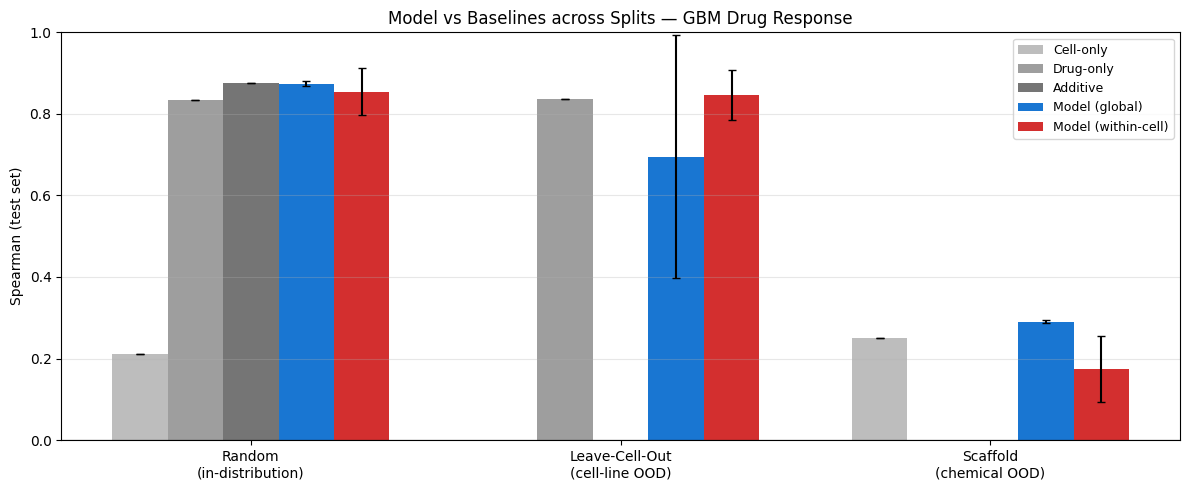

✅ 已保存 OOD_three_split_comparison.png


In [5]:
# ============================================================
# Cell 4: 三 split 对比柱状图
# ============================================================

labels = ['Cell-only', 'Drug-only', 'Additive', 'Model (global)', 'Model (within-cell)']
data, errs = {}, {}
for label in labels:
    vals, err_vals = [], []
    for split in SPLIT_NAMES:
        r = results[split]
        if label == 'Cell-only':
            vals.append(r['baselines']['cell_only']); err_vals.append(0)
        elif label == 'Drug-only':
            vals.append(r['baselines']['drug_only']); err_vals.append(0)
        elif label == 'Additive':
            vals.append(r['baselines']['additive']); err_vals.append(0)
        elif label == 'Model (global)':
            vals.append(r['model_global']['mean']); err_vals.append(r['model_global']['std'])
        elif label == 'Model (within-cell)':
            vals.append(r['model_within_cell']['mean']); err_vals.append(r['model_within_cell']['std'])
    data[label] = vals
    errs[label] = err_vals

x = np.arange(len(SPLIT_NAMES))
width = 0.15
fig, ax = plt.subplots(figsize=(12, 5))
colors = ['#bdbdbd', '#9e9e9e', '#757575', '#1976d2', '#d32f2f']
for i, label in enumerate(labels):
    ax.bar(x + (i - 2) * width, data[label], width,
           yerr=errs[label], capsize=3, label=label, color=colors[i])
ax.set_xticks(x)
ax.set_xticklabels(['Random\n(in-distribution)', 'Leave-Cell-Out\n(cell-line OOD)',
                    'Scaffold\n(chemical OOD)'])
ax.set_ylabel('Spearman (test set)')
ax.set_title('Model vs Baselines across Splits — GBM Drug Response')
ax.set_ylim(0, 1.0)
ax.axhline(0, color='k', linewidth=0.8)
ax.legend(loc='upper right', fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('OOD_three_split_comparison.png', dpi=150)
plt.show()
print("✅ 已保存 OOD_three_split_comparison.png")

In [6]:
# ============================================================
# Cell 5（可选）：GNN 药物塔（GINConv）
# ============================================================

ATOM_TYPES = ['C','N','O','S','F','Cl','Br','I','P','B','Si','Se']
ATOM2IDX = {a: i for i, a in enumerate(ATOM_TYPES)}

def smiles_to_pyg(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    xs = []
    for atom in mol.GetAtoms():
        sym = atom.GetSymbol()
        idx = ATOM2IDX.get(sym, len(ATOM_TYPES))
        feat = [0.0] * (len(ATOM_TYPES) + 1)
        feat[idx] = 1.0
        feat += [atom.GetDegree()/4, float(atom.GetIsAromatic()), atom.GetFormalCharge()]
        xs.append(feat)
    x = torch.tensor(xs, dtype=torch.float32)
    if mol.GetNumBonds() == 0:
        edge_index = torch.empty((2, 0), dtype=torch.long)
    else:
        src, dst = [], []
        for b in mol.GetBonds():
            i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx()
            src += [i, j]; dst += [j, i]
        edge_index = torch.tensor([src, dst], dtype=torch.long)
    return Data(x=x, edge_index=edge_index)

class DrugResponseGraphDataset(torch.utils.data.Dataset):
    def __init__(self, df, y_mean=None, y_std=None):
        self.cell_cols = [c for c in df.columns if c.startswith(('PCA_','MUT_','MGMT_'))]
        self.cell = torch.tensor(df[self.cell_cols].values.astype(np.float32))
        self.smiles = df['SMILES'].tolist() if 'SMILES' in df.columns else None
        # 如果 final_df 没保存 SMILES，用 DRUG_NAME 从 drug_info 里补；这里假设 df 有 'SMILES'
        y = df['LN_IC50'].values.astype(np.float32)
        if y_mean is None:
            y_mean, y_std = float(y.mean()), float(y.std())
        self.y_mean, self.y_std = y_mean, y_std
        self.y = torch.tensor((y - y_mean)/y_std, dtype=torch.float32)
        # 缓存图
        self.graphs = [smiles_to_pyg(s) for s in self.smiles]

    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.graphs[i], self.cell[i], self.y[i]

class GNNDrugMLP(nn.Module):
    def __init__(self, node_dim, hidden=256, cell_dim=44):
        super().__init__()
        self.conv1 = GINConv(nn.Sequential(nn.Linear(node_dim, 128), nn.ReLU(), nn.Linear(128, 128)))
        self.conv2 = GINConv(nn.Sequential(nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, hidden)))
        self.cell_net = nn.Sequential(
            nn.Linear(cell_dim, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, hidden))
        self.predictor = nn.Sequential(
            nn.Linear(hidden*2, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 1))

    def forward(self, data, cell):
        x, ei, batch = data.x, data.edge_index, data.batch
        x = F.relu(self.conv1(x, ei))
        x = F.relu(self.conv2(x, ei))
        drug_emb = global_mean_pool(x, batch)
        cell_emb = self.cell_net(cell)
        return self.predictor(torch.cat([drug_emb, cell_emb], dim=1)).squeeze()

# 说明：需要 df 里保存 'SMILES' 列。如果 Day 1 pkl 里没有，需要重新合 SMILES。
# 此处仅提供架构示意，实际接入时按需补齐 SMILES 列。
print("GNN Cell 已就绪，如果 df 里没有 SMILES 列，需要回 Day 1 补合并 drug_info['SMILES']")

GNN Cell 已就绪，如果 df 里没有 SMILES 列，需要回 Day 1 补合并 drug_info['SMILES']


In [7]:
# 看 leave_cell 每个 seed 的具体值
import pickle
with open('OOD_results.pkl', 'rb') as f:
    r = pickle.load(f)

print("leave_cell per-seed Spearman:", r['leave_cell']['model_global']['values'])
print("leave_cell per-seed RMSE:     ", r['leave_cell']['model_rmse'])

leave_cell per-seed Spearman: [0.8462483364353419, 0.8387817339381077, 0.09886499365743595, 0.8476423535220396, 0.8418693844176809]
leave_cell per-seed RMSE:      {'mean': 1.3969938278198242, 'std': 0.6114841767802751}


In [8]:
# ============================================================
# 诊断 seed 2 崩溃原因
# ============================================================
import pandas as pd, numpy as np, torch
from scipy.stats import spearmanr

trainval_df = pd.read_pickle('train_leave_cell.pkl')
test_df     = pd.read_pickle('test_leave_cell.pkl')
from sklearn.model_selection import train_test_split
train_df, val_df = train_test_split(
    trainval_df, test_size=0.15, random_state=42,
    stratify=trainval_df['ModelID'])

print(f"train cells: {train_df['ModelID'].nunique()}, "
      f"val cells: {val_df['ModelID'].nunique()}, "
      f"test cells: {test_df['ModelID'].nunique()}")

# === 1. 逐 epoch 打印 seed 2 的 val 曲线 ===
r2 = train_one_seed(train_df, val_df, test_df, seed=2, epochs=100, patience=15)
print(f"\n[seed 2 复现] test_rmse={r2['test_rmse']:.4f}, "
      f"test_sp={r2['test_spearman']:.4f}, epochs={r2['n_epochs']}")

# === 2. 每个测试细胞系单独看 seed 2 的 Spearman ===
test_preds, test_trues = r2['test_preds'], r2['test_trues']
test_cells = test_df['ModelID'].values
df = pd.DataFrame({'p': test_preds, 't': test_trues, 'c': test_cells})
print("\n[seed 2] 每个测试细胞系的表现:")
for cell, g in df.groupby('c'):
    sp = spearmanr(g['p'], g['t']).correlation
    rmse = np.sqrt(np.mean((g['p'] - g['t'])**2))
    print(f"  {cell}: n={len(g):3d}, sp={sp:+.4f}, rmse={rmse:.3f}, "
          f"pred_mean={g['p'].mean():.2f}, true_mean={g['t'].mean():.2f}")

# === 3. 对照 seed 0 的逐细胞系 ===
r0 = train_one_seed(train_df, val_df, test_df, seed=0)
df0 = pd.DataFrame({'p': r0['test_preds'], 't': r0['test_trues'], 'c': test_cells})
print("\n[seed 0] 每个测试细胞系的表现:")
for cell, g in df0.groupby('c'):
    sp = spearmanr(g['p'], g['t']).correlation
    rmse = np.sqrt(np.mean((g['p'] - g['t'])**2))
    print(f"  {cell}: n={len(g):3d}, sp={sp:+.4f}, rmse={rmse:.3f}")

train cells: 20, val cells: 20, test cells: 4

[seed 2 复现] test_rmse=2.6199, test_sp=0.0989, epochs=21

[seed 2] 每个测试细胞系的表现:
  ACH-000098: n=228, sp=+0.3355, rmse=2.909, pred_mean=3.87, true_mean=2.87
  ACH-000469: n=228, sp=+0.2056, rmse=2.717, pred_mean=2.68, true_mean=2.71
  ACH-000595: n=227, sp=+0.2337, rmse=2.333, pred_mean=3.01, true_mean=3.71
  ACH-000622: n=175, sp=+0.2586, rmse=2.438, pred_mean=3.27, true_mean=3.76

[seed 0] 每个测试细胞系的表现:
  ACH-000098: n=228, sp=+0.9041, rmse=1.001
  ACH-000469: n=228, sp=+0.9091, rmse=1.033
  ACH-000595: n=227, sp=+0.7924, rmse=1.207
  ACH-000622: n=175, sp=+0.7785, rmse=1.101


In [9]:
# nearest-drug baseline for scaffold split
# 用 Morgan 指纹相似度最近的训练集药物均值来预测测试药物
from sklearn.metrics.pairwise import cosine_similarity
trainval_df = pd.read_pickle('train_scaffold.pkl')
test_df_scaf = pd.read_pickle('test_scaffold.pkl')

# 每种药物取一个代表指纹
tr_drug = trainval_df.groupby('DRUG_NAME').agg({
    'Morgan_FP': 'first', 'LN_IC50': 'mean'}).reset_index()
test_drug_names = test_df_scaf['DRUG_NAME'].unique()

tr_fps = np.stack(tr_drug['Morgan_FP'].values)
sim = cosine_similarity(np.stack(
    test_df_scaf.drop_duplicates('DRUG_NAME')['Morgan_FP'].values), tr_fps)
nearest_idx = sim.argmax(axis=1)
nearest_mean = tr_drug.iloc[nearest_idx]['LN_IC50'].values

# 映射回 test_df
nn_map = dict(zip(
    test_df_scaf.drop_duplicates('DRUG_NAME')['DRUG_NAME'].values,
    nearest_mean))
test_df_scaf['pred_nn'] = test_df_scaf['DRUG_NAME'].map(nn_map)
sp_nn = spearmanr(test_df_scaf['pred_nn'], test_df_scaf['LN_IC50']).correlation
print(f"[scaffold] Nearest-drug baseline Spearman = {sp_nn:.4f}")

[scaffold] Nearest-drug baseline Spearman = 0.1445
